CUSTOMER CHURN & RETRACTION PROJECT

In [2]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
customers=pd.read_csv(r"C:\Users\HP\OneDrive\Desktop\python project\FINAL PROJECT 01 CHURN\olist_customers_dataset.csv")
orders=pd.read_csv(r"C:\Users\HP\OneDrive\Desktop\python project\FINAL PROJECT 01 CHURN\olist_orders_dataset.csv")
order_items=pd.read_csv(r"C:\Users\HP\OneDrive\Desktop\python project\FINAL PROJECT 01 CHURN\olist_order_items_dataset.csv")
payments=pd.read_csv(r"C:\Users\HP\OneDrive\Desktop\python project\FINAL PROJECT 01 CHURN\olist_order_payments_dataset.csv")
reviews=pd.read_csv(r"C:\Users\HP\OneDrive\Desktop\python project\FINAL PROJECT 01 CHURN\olist_order_reviews_dataset.csv")

In [4]:
customers.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [5]:
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [6]:
order_items.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [7]:
payments.head()

,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45


In [8]:
reviews.head()

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


In [9]:
print("customers:",customers.shape)
print("orders:",orders.shape)
print("order_items:",order_items.shape)
print("payments:",payments.shape)
print("reviews:",reviews.shape)

customers: (99441, 5)
orders: (99441, 8)
order_items: (112650, 7)
payments: (103886, 5)
reviews: (99224, 7)


In [10]:
customers.columns

Index(['customer_id', 'customer_unique_id', 'customer_zip_code_prefix',
       'customer_city', 'customer_state'],
      dtype='object')

In [11]:
orders.columns

Index(['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp',
       'order_approved_at', 'order_delivered_carrier_date',
       'order_delivered_customer_date', 'order_estimated_delivery_date'],
      dtype='object')

In [12]:
order_items.columns

Index(['order_id', 'order_item_id', 'product_id', 'seller_id',
       'shipping_limit_date', 'price', 'freight_value'],
      dtype='object')

In [13]:
payments.columns

Index(['order_id', 'payment_sequential', 'payment_type',
       'payment_installments', 'payment_value'],
      dtype='object')

In [14]:
reviews.columns

Index(['review_id', 'order_id', 'review_score', 'review_comment_title',
       'review_comment_message', 'review_creation_date',
       'review_answer_timestamp'],
      dtype='object')

In [15]:
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB


In [16]:
date_columns=['order_purchase_timestamp',
              'order_approved_at',
              'order_delivered_carrier_date',
              'order_delivered_customer_date',
              'order_estimated_delivery_date']

for col in date_columns:
    orders[col]=pd.to_datetime(
        orders[col],
        errors='coerce'
        )

In [17]:
#orders[date_columns] = orders[date_columns].astype(str)

In [18]:
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       99441 non-null  object        
 1   customer_id                    99441 non-null  object        
 2   order_status                   99441 non-null  object        
 3   order_purchase_timestamp       99441 non-null  datetime64[ns]
 4   order_approved_at              99281 non-null  datetime64[ns]
 5   order_delivered_carrier_date   97658 non-null  datetime64[ns]
 6   order_delivered_customer_date  96476 non-null  datetime64[ns]
 7   order_estimated_delivery_date  99441 non-null  datetime64[ns]
dtypes: datetime64[ns](5), object(3)
memory usage: 6.1+ MB


In [19]:
customers.isnull().sum()

customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state              0
dtype: int64

In [20]:
orders.isnull().sum()

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

In [21]:
order_items.isnull().sum()

order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64

In [22]:
payments.isnull().sum()

order_id                0
payment_sequential      0
payment_type            0
payment_installments    0
payment_value           0
dtype: int64

In [23]:
reviews.isnull().sum()

review_id                      0
order_id                       0
review_score                   0
review_comment_title       87656
review_comment_message     58247
review_creation_date           0
review_answer_timestamp        0
dtype: int64

In [24]:
customers.duplicated().sum()

np.int64(0)

In [25]:
orders.duplicated().sum()

np.int64(0)

In [26]:
order_items.duplicated().sum()

np.int64(0)

In [27]:
payments.duplicated().sum()

np.int64(0)

In [28]:
reviews.duplicated().sum()

np.int64(0)

In [29]:
customers['customer_id'].nunique()

99441

In [30]:
len(customers)

99441

In [31]:
orders['order_id'].nunique()

99441

In [32]:
len(orders)

99441

In [33]:
order_items['order_id'].nunique()

98666

In [34]:
len(order_items)

112650

In [35]:
payments['order_id'].nunique()

99440

In [36]:
len(payments)

103886

In [37]:
reviews['review_id'].nunique()

98410

In [38]:
len(reviews)

99224

In [39]:
delivered_orders = orders[
    orders['order_status'] == 'delivered'
].copy()

In [40]:
delivered_orders.shape

(96478, 8)

In [41]:
delivered_orders

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26
...,...,...,...,...,...,...,...,...
99436,9c5dedf39a927c1b2549525ed64a053c,39bd1228ee8140590ac3aca26f2dfe00,delivered,2017-03-09 09:54:05,2017-03-09 09:54:05,2017-03-10 11:18:03,2017-03-17 15:08:01,2017-03-28
99437,63943bddc261676b46f01ca7ac2f7bd8,1fca14ff2861355f6e5f14306ff977a7,delivered,2018-02-06 12:58:58,2018-02-06 13:10:37,2018-02-07 23:22:42,2018-02-28 17:37:56,2018-03-02
99438,83c1379a015df1e13d02aae0204711ab,1aa71eb042121263aafbe80c1b562c9c,delivered,2017-08-27 14:46:43,2017-08-27 15:04:16,2017-08-28 20:52:26,2017-09-21 11:24:17,2017-09-27
99439,11c177c8e97725db2631073c19f07b62,b331b74b18dc79bcdf6532d51e1637c1,delivered,2018-01-08 21:28:27,2018-01-08 21:36:21,2018-01-12 15:35:03,2018-01-25 23:32:54,2018-02-15


In [42]:
order_revenue = (
    order_items
    .groupby('order_id')
    .agg(
        product_revenue=('price','sum'),
        freight_cost=('freight_value','sum')
    )
    .reset_index()
)

In [43]:
order_revenue['total_revenue']=(
    order_revenue['product_revenue'] + 
    order_revenue['freight_cost']
)

In [44]:
order_revenue.head()

,order_id,product_revenue,freight_cost,total_revenue
0,00010242fe8c5a6d1ba2dd792cb16214,58.90,13.29,72.19
1,00018f77f2f0320c557190d7a144bdd3,239.90,19.93,259.83
2,000229ec398224ef6ca0657da4fc703e,199.00,17.87,216.87
3,00024acbcdf0a6daa1e931b038114c75,12.99,12.79,25.78
4,00042b26cf59d7ce69dfabb4e55b4fd9,199.90,18.14,218.04


In [45]:
orders_analysis= pd.merge(delivered_orders,order_revenue,on='order_id',how='left')

In [46]:
orders_analysis

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,product_revenue,freight_cost,total_revenue
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,29.99,8.72,38.71
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,118.70,22.76,141.46
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,159.90,19.22,179.12
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,45.00,27.20,72.20
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,19.90,8.72,28.62
...,...,...,...,...,...,...,...,...,...,...,...
96473,9c5dedf39a927c1b2549525ed64a053c,39bd1228ee8140590ac3aca26f2dfe00,delivered,2017-03-09 09:54:05,2017-03-09 09:54:05,2017-03-10 11:18:03,2017-03-17 15:08:01,2017-03-28,72.00,13.08,85.08
96474,63943bddc261676b46f01ca7ac2f7bd8,1fca14ff2861355f6e5f14306ff977a7,delivered,2018-02-06 12:58:58,2018-02-06 13:10:37,2018-02-07 23:22:42,2018-02-28 17:37:56,2018-03-02,174.90,20.10,195.00
96475,83c1379a015df1e13d02aae0204711ab,1aa71eb042121263aafbe80c1b562c9c,delivered,2017-08-27 14:46:43,2017-08-27 15:04:16,2017-08-28 20:52:26,2017-09-21 11:24:17,2017-09-27,205.99,65.02,271.01
96476,11c177c8e97725db2631073c19f07b62,b331b74b18dc79bcdf6532d51e1637c1,delivered,2018-01-08 21:28:27,2018-01-08 21:36:21,2018-01-12 15:35:03,2018-01-25 23:32:54,2018-02-15,359.98,81.18,441.16


In [47]:
orders_analysis.columns

Index(['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp',
       'order_approved_at', 'order_delivered_carrier_date',
       'order_delivered_customer_date', 'order_estimated_delivery_date',
       'product_revenue', 'freight_cost', 'total_revenue'],
      dtype='object')

In [48]:
orders_analysis['delivery_days'] = (
    orders_analysis['order_delivered_customer_date']
    - orders_analysis['order_purchase_timestamp']
).dt.days

In [49]:
orders_analysis['estimated_delivery_days'] = (
    orders_analysis['order_estimated_delivery_date']
    - orders_analysis['order_purchase_timestamp']
).dt.days

In [50]:
orders_analysis['delivery_delay_days']=(
    orders_analysis['order_delivered_customer_date']
    - orders_analysis['order_estimated_delivery_date']
).dt.days

In [52]:
orders_analysis=pd.merge(orders_analysis,
                         customers[
                             ['customer_id',
                             'customer_unique_id',
                             'customer_city',
                             'customer_state']
                             ],on='customer_id',how='left')

In [53]:
review_summary=(
    reviews
    .groupby('order_id')
    .agg(
        review_score=('review_score','mean'),
        has_review=('review_id','count')
    )
    .reset_index()
)

In [56]:
review_summary['has_review']=np.where(
    review_summary['has_review']>0,
    1,
    0
)

In [58]:
order_analysis=pd.merge(orders_analysis,review_summary,on='order_id',how='left')

In [60]:
payment_summary = (
    payments
    .groupby('order_id')
    .agg(
        payment_value=('payment_value', 'sum'),
        payment_installments=('payment_installments', 'mean'),
        payment_type_count=('payment_type', 'nunique')
    )
    .reset_index()
)

In [102]:
order_analysis = order_analysis.merge(
    payment_summary,
    on='order_id',
    how='left'
)

In [103]:
order_analysis.columns

Index(['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp',
       'order_approved_at', 'order_delivered_carrier_date',
       'order_delivered_customer_date', 'order_estimated_delivery_date',
       'product_revenue', 'freight_cost', 'total_revenue', 'delivery_days',
       'estimated_delivery_days', 'delivery_delay_days',
       'customer_unique_id_x', 'customer_city_x', 'customer_state_x',
       'review_score', 'has_review', 'payment_value', 'payment_installments',
       'payment_type_count'],
      dtype='object')

In [108]:
customer_data = (
    order_analysis
    .groupby([
        'customer_unique_id_x',
        'customer_state_x',
        'customer_city_x'
    ])
    .agg(
        total_orders=('order_id', 'nunique'),
        total_revenue=('total_revenue', 'sum'),
        avg_order_value=('total_revenue', 'mean'),
        total_items=('order_id', 'count'),
        avg_delivery_days=('delivery_days', 'mean'),
        avg_delivery_delay=('delivery_delay_days', 'mean'),
        avg_review_score=('review_score', 'mean'),
        payment_type_count=('payment_type_count', 'mean'),
        avg_installments=('payment_installments', 'mean'),
        first_purchase=('order_purchase_timestamp', 'min'),
        last_purchase=('order_purchase_timestamp', 'max')
    )
    .reset_index()
)

In [118]:
reference_date = order_analysis['order_purchase_timestamp'].max()

In [124]:
customer_data['recency_days'] = (reference_date-customer_data['last_purchase']).dt.days

In [127]:
customer_data['customer_lifetime_days'] = (customer_data['last_purchase'] -
                                           customer_data['first_purchase']).dt.days

In [129]:
customer_data['is_repeat_customer'] = np.where(
    customer_data['total_orders'] > 1,
    1,
    0
)

In [133]:
customer_data['is_repeat_customer'].value_counts()

is_repeat_customer
0    90772
1     2699
Name: count, dtype: int64

In [131]:
customer_data['churned'] = np.where(
    customer_data['recency_days'] > 90,
    1,
    0
)

In [132]:
customer_data['churned'].value_counts()

churned
1    74877
0    18594
Name: count, dtype: int64

In [137]:
customer_data['churned'].value_counts(normalize=True) * 100

churned
1    80.107199
0    19.892801
Name: proportion, dtype: float64

In [138]:
customer_data.isnull().sum()

customer_unique_id_x        0
customer_state_x            0
customer_city_x             0
total_orders                0
total_revenue               0
avg_order_value             0
total_items                 0
avg_delivery_days           8
avg_delivery_delay          8
avg_review_score          605
payment_type_count          1
avg_installments            1
first_purchase              0
last_purchase               0
recency_days                0
customer_lifetime_days      0
is_repeat_customer          0
churned                     0
dtype: int64

In [139]:
customer_data['has_review'] = np.where(
    customer_data['avg_review_score'].isna(),
    0,
    1
)

In [144]:
customer_data['avg_review_score'] = (
    customer_data['avg_review_score'].fillna(0)
)

In [154]:
numeric_cols = [
    'avg_delivery_days',
    'avg_delivery_delay',
    'avg_review_score',
    'avg_installments',
    'payment_type_count'
]

for col in numeric_cols:
    customer_data[col] = customer_data[col].fillna(
        customer_data[col].median()
    )

In [157]:
customer_data.shape

(93471, 19)

In [158]:
customer_data.head()

,customer_unique_id_x,customer_state_x,customer_city_x,total_orders,total_revenue,avg_order_value,total_items,avg_delivery_days,avg_delivery_delay,avg_review_score,payment_type_count,avg_installments,first_purchase,last_purchase,recency_days,customer_lifetime_days,is_repeat_customer,churned,has_review
0,0000366f3b9a7992bf8c76cfdf3221e2,SP,cajamar,1,141.90,141.90,1,6.0,-5.0,5.0,1.0,8.0,2018-05-10 10:56:27,2018-05-10 10:56:27,111,0,0,1,1
1,0000b849f77a49e4a4ce2b2a4ca5be3f,SP,osasco,1,27.19,27.19,1,3.0,-5.0,4.0,1.0,1.0,2018-05-07 11:11:27,2018-05-07 11:11:27,114,0,0,1,1
2,0000f46a3911fa3c0805444483337064,SC,sao jose,1,86.22,86.22,1,25.0,-2.0,3.0,1.0,8.0,2017-03-10 21:05:03,2017-03-10 21:05:03,536,0,0,1,1
3,0000f6ccb0745a6a4b88665a16c9f078,PA,belem,1,43.62,43.62,1,20.0,-12.0,4.0,1.0,4.0,2017-10-12 20:29:41,2017-10-12 20:29:41,320,0,0,1,1
4,0004aac84e0df4da2b147fca70cf8255,SP,sorocaba,1,196.89,196.89,1,13.0,-8.0,5.0,1.0,6.0,2017-11-14 19:45:42,2017-11-14 19:45:42,287,0,0,1,1


In [159]:
customer_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 93471 entries, 0 to 93470
Data columns (total 19 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   customer_unique_id_x    93471 non-null  object        
 1   customer_state_x        93471 non-null  object        
 2   customer_city_x         93471 non-null  object        
 3   total_orders            93471 non-null  int64         
 4   total_revenue           93471 non-null  float64       
 5   avg_order_value         93471 non-null  float64       
 6   total_items             93471 non-null  int64         
 7   avg_delivery_days       93471 non-null  float64       
 8   avg_delivery_delay      93471 non-null  float64       
 9   avg_review_score        93471 non-null  float64       
 10  payment_type_count      93471 non-null  float64       
 11  avg_installments        93471 non-null  float64       
 12  first_purchase          93471 non-null  dateti

In [162]:
customer_data.isnull().sum()

customer_unique_id_x      0
customer_state_x          0
customer_city_x           0
total_orders              0
total_revenue             0
avg_order_value           0
total_items               0
avg_delivery_days         0
avg_delivery_delay        0
avg_review_score          0
payment_type_count        0
avg_installments          0
first_purchase            0
last_purchase             0
recency_days              0
customer_lifetime_days    0
is_repeat_customer        0
churned                   0
has_review                0
dtype: int64

In [170]:
customer_data.to_csv(r"C:\Users\HP\OneDrive\Desktop\python project\FINAL PROJECT 01 CHURN\customer_churn_analysis.csv",index=False)

EDA

In [ ]:
#How large is the churn problem?

In [172]:
churn_rate = customer_data['churned'].mean() * 100

print(f"Churn Rate: {churn_rate:.2f}%")

Churn Rate: 80.11%


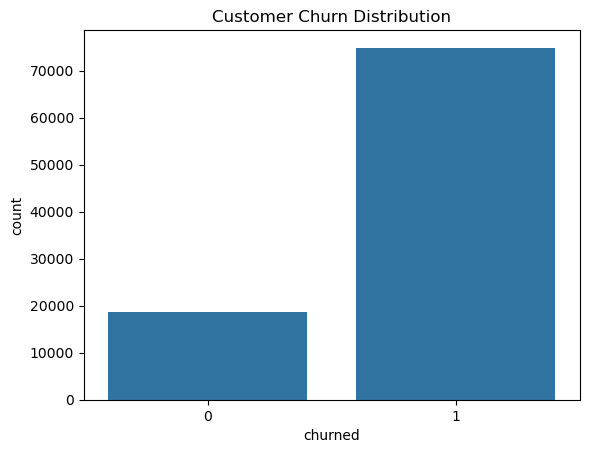

In [173]:
sns.countplot(
    data=customer_data,
    x='churned'
)

plt.title('Customer Churn Distribution')
plt.show()

In [ ]:
#Revenue from Churned Customers

In [174]:
revenue_churn = (
    customer_data
    .groupby('churned')['total_revenue']
    .sum()
)

print(revenue_churn)

churned
0     3129288.89
1    12290484.86
Name: total_revenue, dtype: float64


In [ ]:
#Does Delivery Affect Churn?

In [175]:
customer_data.groupby('churned')[
    'avg_delivery_days'
].mean()

churned
0     8.259867
1    13.057515
Name: avg_delivery_days, dtype: float64

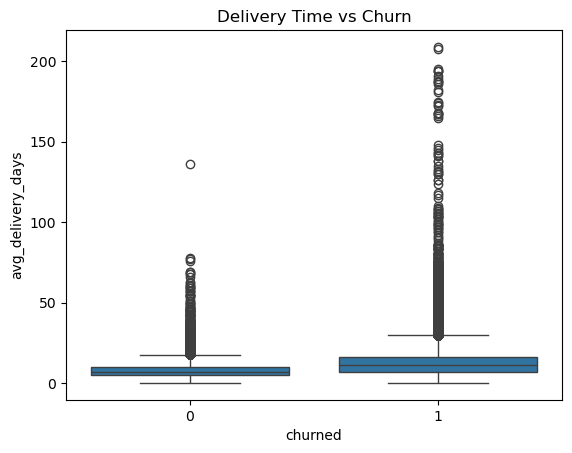

In [176]:
sns.boxplot(
    data=customer_data,
    x='churned',
    y='avg_delivery_days'
)

plt.title('Delivery Time vs Churn')
plt.show()

In [ ]:
#Does Customer Satisfaction Matter?

In [177]:
customer_data.groupby('churned')[
    'avg_review_score'
].mean()

churned
0    4.290122
1    4.086233
Name: avg_review_score, dtype: float64

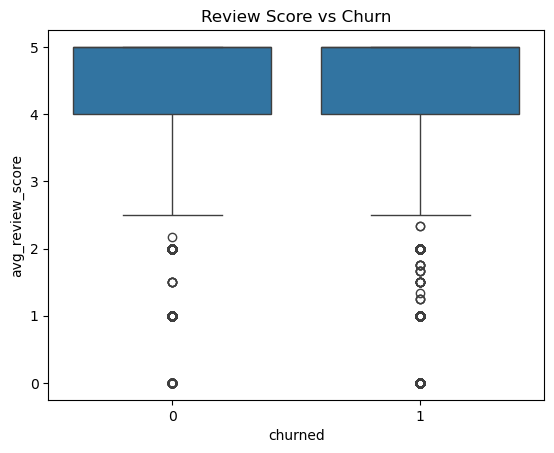

In [178]:
sns.boxplot(
    data=customer_data,
    x='churned',
    y='avg_review_score'
)

plt.title('Review Score vs Churn')
plt.show()

In [ ]:
#Repeat Customers        Q. Are repeat customers behaving differently from one-time customers?

In [179]:
pd.crosstab(
    customer_data['is_repeat_customer'],
    customer_data['churned'],
    normalize='index'
) * 100

churned,0,1
is_repeat_customer,,
0,19.835412,80.164588
1,21.822897,78.177103


In [ ]:
#Churn by State

In [185]:
state_churn = (
    customer_data
    .groupby('customer_state_x')
    .agg(
        customers=('customer_unique_id_x', 'count'),
        churn_rate=('churned', 'mean')
    )
    .reset_index()
)

state_churn['churn_rate'] *= 100

state_churn.sort_values(
    'churn_rate',
    ascending=False
).head(10)

,customer_state_x,customers,churn_rate
0,AC,76,86.842105
20,RO,231,84.848485
9,MA,700,83.857143
1,AL,388,83.505155
3,AP,66,83.333333
13,PA,922,83.297180
5,CE,1259,83.161239
12,MT,856,83.060748
23,SC,3451,82.700666
16,PI,464,82.543103


In [ ]:
#Churn by Payment Type

In [186]:
primary_payment = (
    payments
    .groupby('order_id')
    .first()
    .reset_index()
)

In [ ]:
#Create RFM Segmentation

In [188]:
customer_data['R_score'] = pd.qcut(
    customer_data['recency_days'],
    5,
    labels=[5,4,3,2,1]
)

In [189]:
customer_data['F_score'] = pd.qcut(
    customer_data['total_orders'].rank(method='first'),
    5,
    labels=[1,2,3,4,5]
)

In [190]:
customer_data['M_score'] = pd.qcut(
    customer_data['total_revenue'].rank(method='first'),
    5,
    labels=[1,2,3,4,5]
)

In [191]:
customer_data['RFM_score'] = (
    customer_data['R_score'].astype(int) +
    customer_data['F_score'].astype(int) +
    customer_data['M_score'].astype(int)
)

In [ ]:
#Create Retention Segments

In [193]:
customer_data['retention_segment'] = np.select(
    [
        (customer_data['RFM_score'] >= 13),
        (customer_data['RFM_score'].between(10, 12)),
        (customer_data['RFM_score'].between(7, 9)),
        (customer_data['RFM_score'] <= 6)
    ],
    [
        'High Value Loyal',
        'Potential Loyalist',
        'At Risk',
        'Low Engagement'
    ],
    default='Other'
)

In [ ]:
#Retention Strategy Simulation

In [196]:
target = customer_data[
    (customer_data['retention_segment'] == 'At Risk') &
    (customer_data['churned'] == 1)
].copy()

In [197]:
campaign_cost_per_customer = 20
expected_recovery_rate = 0.10

target_customers = len(target)

campaign_cost = (
    target_customers *
    campaign_cost_per_customer
)

potential_recovered_revenue = (
    target['total_revenue'].sum() *
    expected_recovery_rate
)

net_impact = (
    potential_recovered_revenue -
    campaign_cost
)

print("Target Customers:", target_customers)
print("Campaign Cost:", campaign_cost)
print("Potential Revenue:", potential_recovered_revenue)
print("Net Impact:", net_impact)

Target Customers: 33964
Campaign Cost: 679280
Potential Revenue: 470018.1640000001
Net Impact: -209261.8359999999


In [201]:
customer_data.to_csv(r"C:\Users\HP\OneDrive\Desktop\python project\FINAL PROJECT 01 CHURN\Customer_Churn_Final.csv",index=False)

In [202]:
state_churn.to_csv(r"C:\Users\HP\OneDrive\Desktop\python project\FINAL PROJECT 01 CHURN\Churn_By_State.csv",index=False)